# what are the most demanded skills for the top 3 most popular data roles? 

## Methodology

  ### 1. Clean-up skill column
  ### 2. Calculate skill count based on  job_title_short
  ### 3. Calculate skill percentage
  ### 4. Plot final findings

In [2]:
# Importing Libraries
import ast
import seaborn as sns
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [3]:
df_India = df[df['job_country'] == 'India']

In [4]:
df_skills = df_India.explode('job_skills')

In [5]:
df_skills = [['job_title','job_skills']]

In [10]:
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

df_skills = df.explode('job_skills')

df_skills_count = df_skills.groupby(['job_title_short', 'job_skills']).size().reset_index(name='skill_count')

df_skills_count = df_skills_count.sort_values(by='skill_count', ascending=False)

df_skills_count

,job_title_short,job_skills,skill_count
1066,Data Scientist,python,113711
865,Data Engineer,sql,113130
830,Data Engineer,python,108022
625,Data Analyst,sql,92428
1101,Data Scientist,sql,78982
...,...,...,...
462,Data Analyst,chainer,1
432,Cloud Engineer,wrike,1
410,Cloud Engineer,theano,1
24,Business Analyst,chainer,1


In [11]:
type(df_skills_count)

pandas.DataFrame

In [15]:
df_skills_count = df_skills_count.reset_index()
df_skills_count = df_skills_count.sort_values(by='skill_count', ascending=False)

df_skills_count

,index,job_title_short,job_skills,skill_count
0,1066,Data Scientist,python,113711
1,865,Data Engineer,sql,113130
2,830,Data Engineer,python,108022
3,625,Data Analyst,sql,92428
4,1101,Data Scientist,sql,78982
...,...,...,...,...
2251,462,Data Analyst,chainer,1
2252,432,Cloud Engineer,wrike,1
2253,410,Cloud Engineer,theano,1
2254,24,Business Analyst,chainer,1


In [17]:
job_titles = df_skills_count['job_title_short'].unique().tolist()

job_titles = sorted(job_titles[:3])

job_titles

['Data Analyst', 'Data Engineer', 'Data Scientist']

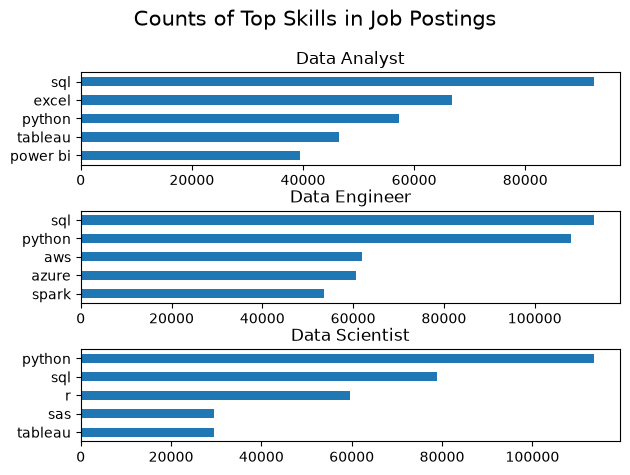

In [25]:

fig, ax = plt.subplots(len(job_titles), 1)

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_count[
        df_skills_count['job_title_short'] == job_title
    ].head(5)

    df_plot.plot(
        kind='barh',
        x='job_skills',
        y='skill_count',
        ax=ax[i],
        title=job_title
    )

    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)

fig.suptitle('Counts of Top Skills in Job Postings', fontsize=15)

fig.tight_layout()
fig.subplots_adjust(hspace=0.5)

plt.show()



In [26]:
df_jobs_total_count = df_India['job_title_short'].value_counts().reset_index(name = 'jobs_total')

In [27]:
df_skills_count

,index,job_title_short,job_skills,skill_count
0,1066,Data Scientist,python,113711
1,865,Data Engineer,sql,113130
2,830,Data Engineer,python,108022
3,625,Data Analyst,sql,92428
4,1101,Data Scientist,sql,78982
...,...,...,...,...
2251,462,Data Analyst,chainer,1
2252,432,Cloud Engineer,wrike,1
2253,410,Cloud Engineer,theano,1
2254,24,Business Analyst,chainer,1


In [35]:
df_job_title_count = df['job_title_short'].value_counts().reset_index()

df_job_title_count.columns = ['job_title_short', 'jobs_total']

df_skills_perc = pd.merge(
    df_skills_count,
    df_job_title_count,
    how='left',
    on='job_title_short'
)

df_skills_perc['skill_perc'] = (
    100 * df_skills_perc['skill_count'] / df_skills_perc['jobs_total']
)

df_skills_perc






,index,job_title_short,job_skills,skill_count,jobs_total,skill_perc
0,1066,Data Scientist,python,113711,172286,66.001300
1,865,Data Engineer,sql,113130,186241,60.743875
2,830,Data Engineer,python,108022,186241,58.001192
3,625,Data Analyst,sql,92428,196075,47.139105
4,1101,Data Scientist,sql,78982,172286,45.843539
...,...,...,...,...,...,...
2251,462,Data Analyst,chainer,1,196075,0.000510
2252,432,Cloud Engineer,wrike,1,12331,0.008110
2253,410,Cloud Engineer,theano,1,12331,0.008110
2254,24,Business Analyst,chainer,1,49063,0.002038


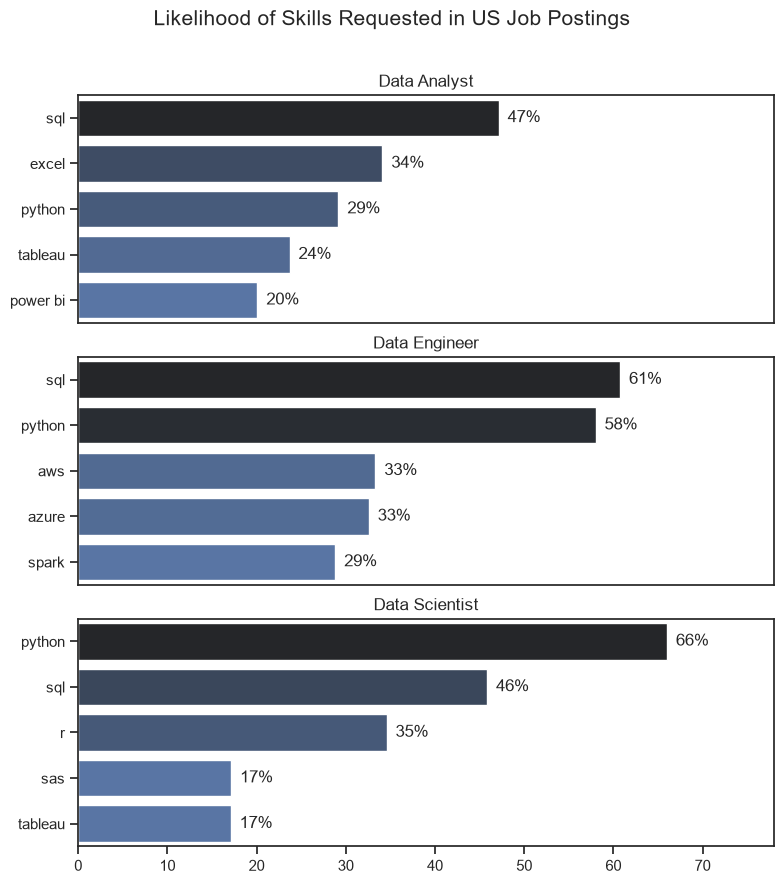

In [53]:


fig, ax = plt.subplots(len(job_titles), 1, figsize=(8, 3 * len(job_titles)))

sns.set_theme(style='ticks')

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_perc[
        df_skills_perc['job_title_short'] == job_title
    ].head(5)

    sns.barplot(
        data=df_plot,
        x='skill_perc',
        y='job_skills',
        ax=ax[i],
        hue='skill_count',
        palette='dark:b_r',
        legend=False
    )

    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].set_xlim(0, 78)

    for n, v in enumerate(df_plot['skill_perc']):
        ax[i].text(v + 1, n, f'{v:.0f}%', va='center')

    if i != len(job_titles) - 1:
        ax[i].set_xticks([])

fig.suptitle(
    'Likelihood of Skills Requested in US Job Postings',
    fontsize=15
)

fig.tight_layout(h_pad=0.8, rect=[0, 0, 1, 0.97])

plt.show()



